In [100]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit,transpile
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram

In [101]:
g = 0.5
delta_t = 1
omega = 2*g
N = 30
simualtor_aer = AerSimulator(method="density_matrix")

### METHOD 1
Obtaining the state at the end of each repetition
No noise

[np.float64(0.5000000000000003), np.float64(0.15522672940110488), np.float64(-0.11030080245148433), np.float64(-0.3147971372434938), np.float64(-0.4722902252543515), np.float64(-0.5935837085650604), np.float64(-0.686998024580192), np.float64(-0.7589411677597934), np.float64(-0.8143482624252639), np.float64(-0.8570201002626032), np.float64(-0.8898838653708457), np.float64(-0.9151939319587131), np.float64(-0.9346865089221971), np.float64(-0.9496987395442804), np.float64(-0.96126042626599), np.float64(-0.970164672624577), np.float64(-0.9770222882236518), np.float64(-0.9823036887836579), np.float64(-0.9863711655140531), np.float64(-0.9895037374074998), np.float64(-0.9919162912628863), np.float64(-0.9937743223961276), np.float64(-0.9952052872155809), np.float64(-0.996307346421091), np.float64(-0.9971560985888159), np.float64(-0.9978097660493447), np.float64(-0.9983131887977063), np.float64(-0.99870090040777), np.float64(-0.9989994969512669), np.float64(-0.9992294614235028)]


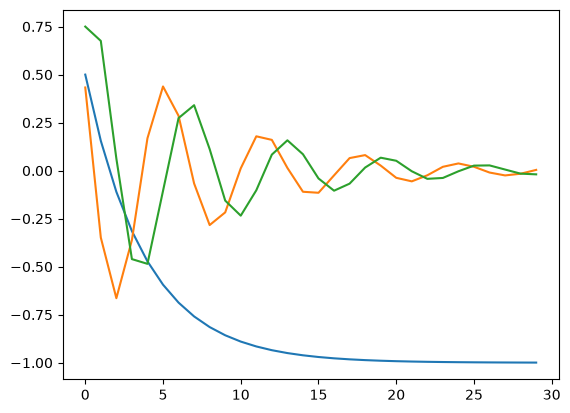

In [ ]:
qc = QuantumCircuit(2,2)
qc.qubits
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.save_density_matrix(label=f"psi_{0}")
for i in range(1,N):
    qc.rxx(g*delta_t,0,1)
    qc.ryy(g*delta_t,0,1)
    qc.rz(-omega*delta_t,0)
    qc.reset(1)
    qc.save_density_matrix(label=f"psi_{i}")
#qc.draw('mpl')


qc_aer = transpile(qc, backend=simualtor_aer)
result = simualtor_aer.run(qc_aer).result()
data = result.data(0)
sz =[]
sy = []
sx = []
for i in range(0,N):
    psi_0 = data[f"psi_{i}"]
    #rho_10 = qi.partial_trace(qi.DensityMatrix(psi_0),[1])

    Z0 = qi.SparsePauliOp("IZ")  # Z sobre el qubit 0
    X0 = qi.SparsePauliOp("IX")
    Y0 = qi.SparsePauliOp("IY")

    exp_z0 = psi_0.expectation_value(-Z0).real
    exp_y0 = psi_0.expectation_value(-Y0).real
    exp_x0 = psi_0.expectation_value(X0).real
    sz.append(exp_z0)
    sx.append(exp_x0)
    sy.append(exp_y0)
print(sz)


time = np.arange(N) * delta_t
plt.plot(time, sz)
plt.plot(time, sx)
plt.plot(time, sy)

datos = np.column_stack((time, sx, sy, sz))

np.savetxt(
    "qiskit1_sxsysz.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

### Method 2
Measuring at the end of the circuit

In [163]:
sz_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.measure(0,0)
    #qc.draw('mpl')
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00', 0) - (1024-(results.get('00', 0)))) / 1024
    sz_2.append(-valor)


In [168]:
sx_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.h(0)
    qc.measure(0,0)
    #qc.draw('mpl')
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    #print(results)
    valor = (results.get('00', 0) - (1024-(results.get('00', 0)))) / 1024
    sx_2.append(valor)

In [169]:
sy_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    #qc.draw('mpl')
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    #print(results)
    valor = (results.get('00', 0) - (1024-(results.get('00', 0)))) / 1024
    sy_2.append(-valor)

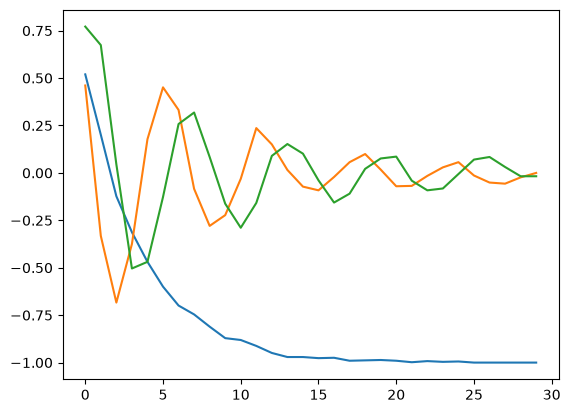

In [171]:
time = np.arange(N) * delta_t
plt.plot(time, sz_2)
plt.plot(time, sx_2)
plt.plot(time, sy_2)

datos = np.column_stack((time, sx_2, sy_2, sz_2))

np.savetxt(
    "qiskit2_sxsysz.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
)

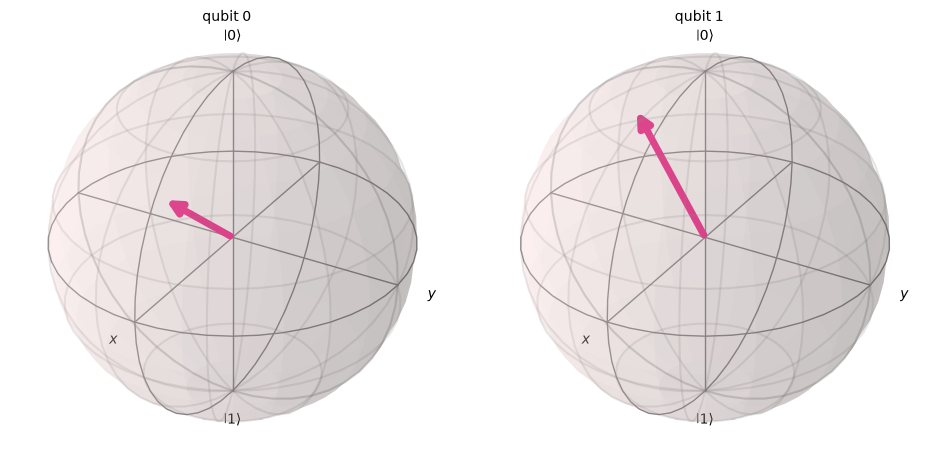

In [149]:
psi.probabilities()
psi.draw('bloch')

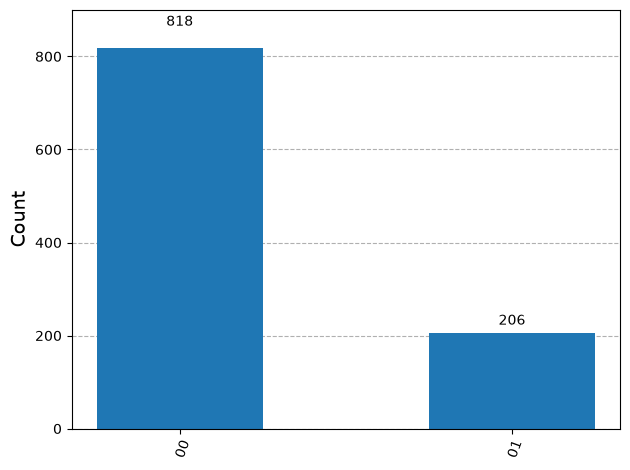

In [49]:
counts = psi.sample_counts(shots = 1024)
plot_histogram(counts)

In [53]:
psi.draw('latex')

<IPython.core.display.Latex object>

In [51]:
rho = qi.DensityMatrix(psi)
rho

DensityMatrix([[0.79572406-4.85605690e-19j, 0.40272255-1.90216447e-02j,
                0.        -0.00000000e+00j, 0.        -0.00000000e+00j],
               [0.40272255+1.90216447e-02j, 0.20427594+3.60710840e-19j,
                0.        +0.00000000e+00j, 0.        +0.00000000e+00j],
               [0.        +0.00000000e+00j, 0.        +0.00000000e+00j,
                0.        +0.00000000e+00j, 0.        +0.00000000e+00j],
               [0.        +0.00000000e+00j, 0.        +0.00000000e+00j,
                0.        +0.00000000e+00j, 0.        +0.00000000e+00j]],
              dims=(2, 2))


In [52]:
rho1 = qi.partial_trace(rho,[1])
rho1

DensityMatrix([[0.79572406-4.85605690e-19j, 0.40272255-1.90216447e-02j],
               [0.40272255+1.90216447e-02j, 0.20427594+3.60710840e-19j]],
              dims=(2,))


In [66]:
from qiskit.providers.basic_provider import BasicSimulator

simulator_basic = BasicSimulator()


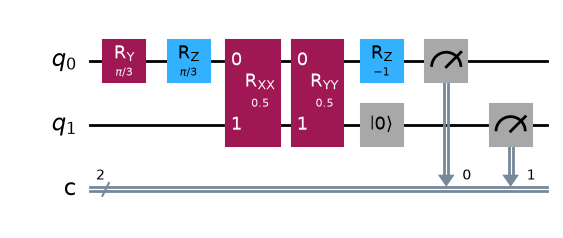

In [83]:
qc = QuantumCircuit(2,2)
qc.qubits
qc.ry(np.pi/3,0)
qc.rz(np.pi/3,0)
for i in range(0,1):
    qc.rxx(g*delta_t,0,1)
    qc.ryy(g*delta_t,0,1)
    qc.rz(-omega*delta_t,0)
qc.reset(1)
psi = qi.Statevector(qc)
qc.measure(0,0)
qc.measure(1,1)
qc.draw('mpl')

In [84]:
job = simulator_basic.run(qc,shots = 1024)
results = job.result()
print(results)

Result(backend_name='basic_simulator', backend_version='0.1', job_id='d6df115a-525e-4bd4-9d28-afda3e594de4', success=True, results=[ExperimentResult(shots=1024, success=True, meas_level=2, data=ExperimentResultData(counts={'0x0': 813, '0x1': 211}, memory=['0x0', '0x0', '0x1', '0x0', '0x0', '0x1', '0x0', '0x1', '0x1', '0x1', '0x1', '0x1', '0x0', '0x1', '0x0', '0x1', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x1', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x1', '0x1', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x0', '0x0', '0x1', '0x0', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x0', '0x1', '0x0', '0x1', '0x0', '0x0', '0x1', '0x0', '0x1', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x0', '0x1', '0x0', '0x1', '0x1', '0x0', '0x0', '0x1', '0x0', '0x0', '0x0', '0

In [85]:
results.get_counts()

{'00': 813, '01': 211}